# ML from Scratch - 1 - Linear Regression

## Importing

In [1]:
import importlib
import my_linear_regression

importlib.reload(my_linear_regression)
from my_linear_regression import Linear_Regression

## Synthetic Data

In [2]:
import numpy as np

np.random.seed(42)

X = np.random.randn(10, 5)

weights = np.random.randn(X.shape[1])

y = X @ weights.T + 5 + np.random.randn(10)

print(f'X = {X}')
print(f'{100*'='}')
print(f'weights = {weights}')
print(f'{100*'='}')
print(f'y = {y}')

X = [[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
 [-0.23413696  1.57921282  0.76743473 -0.46947439  0.54256004]
 [-0.46341769 -0.46572975  0.24196227 -1.91328024 -1.72491783]
 [-0.56228753 -1.01283112  0.31424733 -0.90802408 -1.4123037 ]
 [ 1.46564877 -0.2257763   0.0675282  -1.42474819 -0.54438272]
 [ 0.11092259 -1.15099358  0.37569802 -0.60063869 -0.29169375]
 [-0.60170661  1.85227818 -0.01349722 -1.05771093  0.82254491]
 [-1.22084365  0.2088636  -1.95967012 -1.32818605  0.19686124]
 [ 0.73846658  0.17136828 -0.11564828 -0.3011037  -1.47852199]
 [-0.71984421 -0.46063877  1.05712223  0.34361829 -1.76304016]]
weights = [ 0.32408397 -0.38508228 -0.676922    0.61167629  1.03099952]
y = [6.39725496 3.22949491 1.60745845 3.3148362  5.05902651 4.07755041
 4.11626133 4.13466725 2.34687908 3.43351999]


### Using the Normal Equation

In [3]:
model_normal = Linear_Regression(mode='normal_equation')

model_normal.fit(X, y)

In [4]:
from sklearn.metrics import mean_squared_error

y_pred_normal = model_normal.predict(X)

mse_normal = mean_squared_error(y_pred_normal, y)

print(f'MSE for Linear Regression using the Normal Equation = {mse_normal}')

MSE for Linear Regression using the Normal Equation = 0.37496345324714425


### Using Gradient Descent

In [5]:
model_gradient = Linear_Regression(mode='gradient_descent')

model_gradient.fit(X, y)

In [6]:
y_pred_gradient = model_gradient.predict(X)

mse_gradient = mean_squared_error(y_pred_gradient, y)

print(f'MSE for Linear Regression using Gradient Descent = {mse_gradient}')

MSE for Linear Regression using Gradient Descent = 0.37543055007721704


In [7]:
mse_normal, mse_gradient

(0.37496345324714425, 0.37543055007721704)

## House Prices

In [8]:
import pandas as pd

train_df = pd.read_csv('../data/house_prices/train.csv').set_index('Id')

train_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### EDA

In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt    

In [10]:
train_df.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [11]:
highest_std = train_df.std(numeric_only=True).sort_values(ascending=False).head(10).index

highest_std

Index(['SalePrice', 'LotArea', 'GrLivArea', 'MiscVal', 'BsmtFinSF1',
       'BsmtUnfSF', 'TotalBsmtSF', '2ndFlrSF', '1stFlrSF', 'GarageArea'],
      dtype='object')

In [12]:
train_df[highest_std].describe()

,SalePrice,LotArea,GrLivArea,MiscVal,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,2ndFlrSF,1stFlrSF,GarageArea
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,180921.195890,10516.828082,1515.463699,43.489041,443.639726,567.240411,1057.429452,346.992466,1162.626712,472.980137
std,79442.502883,9981.264932,525.480383,496.123024,456.098091,441.866955,438.705324,436.528436,386.587738,213.804841
min,34900.000000,1300.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000
25%,129975.000000,7553.500000,1129.500000,0.000000,0.000000,223.000000,795.750000,0.000000,882.000000,334.500000
50%,163000.000000,9478.500000,1464.000000,0.000000,383.500000,477.500000,991.500000,0.000000,1087.000000,480.000000
75%,214000.000000,11601.500000,1776.750000,0.000000,712.250000,808.000000,1298.250000,728.000000,1391.250000,576.000000
max,755000.000000,215245.000000,5642.000000,15500.000000,5644.000000,2336.000000,6110.000000,2065.000000,4692.000000,1418.000000


In [13]:
lower = train_df[highest_std].quantile(0.1)
upper = train_df[highest_std].quantile(0.9)

train_df[highest_std] = train_df[highest_std].clip(lower=lower, upper=upper, axis=1)

In [14]:
train_df[highest_std].describe()

,SalePrice,LotArea,GrLivArea,MiscVal,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,2ndFlrSF,1stFlrSF,GarageArea
count,1460.000000,1460.000000,1460.000000,1460.0,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,175074.132877,9588.797397,1481.165616,0.0,415.410959,546.120822,1053.266164,323.711096,1147.682466,475.556575
std,55254.049599,2844.216627,400.894396,0.0,383.231034,371.795529,313.937180,390.649745,306.006398,161.642443
min,106475.000000,5000.000000,912.000000,0.0,0.000000,74.900000,636.900000,0.000000,756.900000,240.000000
25%,129975.000000,7553.500000,1129.500000,0.0,0.000000,223.000000,795.750000,0.000000,882.000000,334.500000
50%,163000.000000,9478.500000,1464.000000,0.0,383.500000,477.500000,991.500000,0.000000,1087.000000,480.000000
75%,214000.000000,11601.500000,1776.750000,0.0,712.250000,808.000000,1298.250000,728.000000,1391.250000,576.000000
max,278000.000000,14381.700000,2158.300000,0.0,1065.500000,1232.000000,1602.200000,954.200000,1680.000000,757.100000


In [15]:
cols_over_50_na = train_df.columns[train_df.isna().mean() > 0.5]

cols_over_50_na

Index(['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature'], dtype='object')

In [16]:
cols_over_50_zero = train_df.columns[(train_df == 0).mean() > 0.5]

cols_over_50_zero

Index(['MasVnrArea', 'BsmtFinSF2', '2ndFlrSF', 'LowQualFinSF', 'BsmtFullBath',
       'BsmtHalfBath', 'HalfBath', 'WoodDeckSF', 'EnclosedPorch', '3SsnPorch',
       'ScreenPorch', 'PoolArea', 'MiscVal'],
      dtype='object')

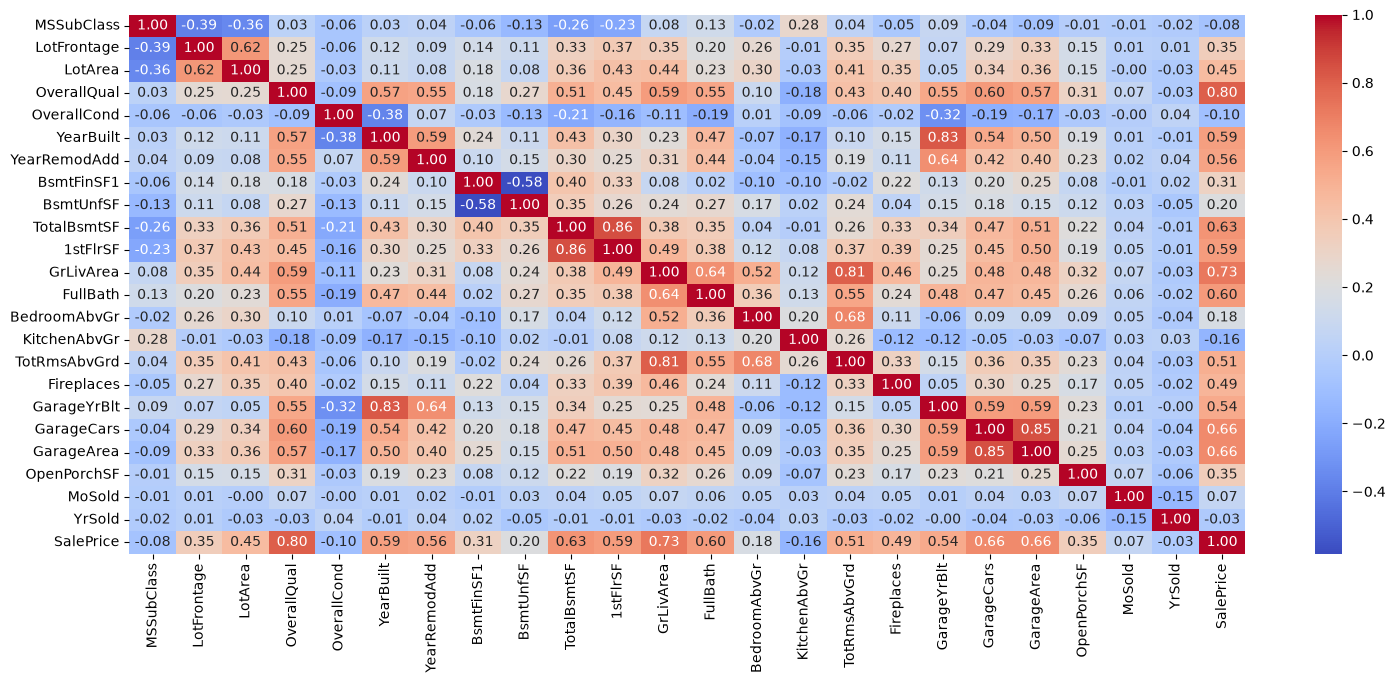

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = train_df.drop(columns=cols_over_50_na.union(cols_over_50_zero)).corr(numeric_only=True)

plt.figure(figsize=(18, 7))

sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".2f",)
plt.show()

In [18]:
cols_high_corr = ["GarageYrBlt", "1stFlrSF", "GarageArea", "TotRmsAbvGrd", "LotFrontage"]

In [19]:
train_df.select_dtypes('object').nunique().sort_values(ascending=False)

Neighborhood     25
Exterior2nd      16
Exterior1st      15
Condition1        9
SaleType          9
HouseStyle        8
RoofMatl          8
Condition2        8
Functional        7
BsmtFinType2      6
RoofStyle         6
BsmtFinType1      6
SaleCondition     6
Heating           6
Foundation        6
GarageType        6
ExterCond         5
LotConfig         5
MSZoning          5
GarageCond        5
GarageQual        5
HeatingQC         5
Electrical        5
BldgType          5
FireplaceQu       5
LandContour       4
LotShape          4
KitchenQual       4
MiscFeature       4
Fence             4
BsmtCond          4
ExterQual         4
BsmtExposure      4
BsmtQual          4
LandSlope         3
PoolQC            3
GarageFinish      3
PavedDrive        3
MasVnrType        3
Utilities         2
Alley             2
Street            2
CentralAir        2
dtype: int64

In [20]:
for col in train_df.select_dtypes('object').columns:
    print(col, train_df[col].unique())

MSZoning ['RL' 'RM' 'C (all)' 'FV' 'RH']
Street ['Pave' 'Grvl']
Alley [nan 'Grvl' 'Pave']
LotShape ['Reg' 'IR1' 'IR2' 'IR3']
LandContour ['Lvl' 'Bnk' 'Low' 'HLS']
Utilities ['AllPub' 'NoSeWa']
LotConfig ['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']
LandSlope ['Gtl' 'Mod' 'Sev']
Neighborhood ['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']
Condition1 ['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']
Condition2 ['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']
BldgType ['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']
HouseStyle ['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']
RoofStyle ['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']
RoofMatl ['CompShg' 'WdShngl' 'Metal' 'WdShake' 'Membran' 'Tar&Grv' 'Roll'
 'ClyTile']
Exterior1st ['VinylSd' 'MetalSd'

### Preprocessing

In [21]:
target = 'SalePrice'

X = train_df.drop(target, axis=1)
y = train_df[target]

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

In [23]:
cols_to_drop = list(set(cols_high_corr) | set(cols_over_50_na) | set(cols_over_50_zero))

cols_to_drop

['ScreenPorch',
 'MiscFeature',
 'MasVnrType',
 'GarageYrBlt',
 'TotRmsAbvGrd',
 'WoodDeckSF',
 'LowQualFinSF',
 'Fence',
 'BsmtHalfBath',
 'GarageArea',
 'LotFrontage',
 'BsmtFullBath',
 'PoolQC',
 'BsmtFinSF2',
 'PoolArea',
 '2ndFlrSF',
 'HalfBath',
 'MasVnrArea',
 '1stFlrSF',
 'EnclosedPorch',
 '3SsnPorch',
 'MiscVal',
 'Alley']

In [24]:
num_cols = X.drop(columns=cols_to_drop).select_dtypes('number').columns

num_cols

Index(['MSSubClass', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt',
       'YearRemodAdd', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', 'GrLivArea',
       'FullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'Fireplaces', 'GarageCars',
       'OpenPorchSF', 'MoSold', 'YrSold'],
      dtype='object')

In [25]:
obj_cols = X.drop(columns=cols_to_drop).select_dtypes('object').columns

obj_cols

Index(['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
       'PavedDrive', 'SaleType', 'SaleCondition'],
      dtype='object')

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
)

num_pipeline

,steps,"[('simpleimputer', ...), ('standardscaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [27]:
from sklearn.preprocessing import OneHotEncoder

obj_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first', min_frequency=10),
)

obj_pipeline

,steps,"[('simpleimputer', ...), ('onehotencoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [28]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('obj', obj_pipeline, obj_cols),
], remainder='drop')

preprocessor.set_output(transform="pandas")

preprocessor

,transformers,"[('num', ...), ('obj', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [29]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_full_preprocessed = preprocessor.transform(X)

c:\Users\Seif Adin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [9, 13, 14, 27] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Seif Adin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [9, 13, 14, 27] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [30]:
X_train_preprocessed.head()

,num__MSSubClass,num__LotArea,num__OverallQual,num__OverallCond,num__YearBuilt,num__YearRemodAdd,num__BsmtFinSF1,num__BsmtUnfSF,num__TotalBsmtSF,num__GrLivArea,...,obj__GarageCond_infrequent_sklearn,obj__PavedDrive_P,obj__PavedDrive_Y,obj__SaleType_New,obj__SaleType_WD,obj__SaleType_infrequent_sklearn,obj__SaleCondition_Family,obj__SaleCondition_Normal,obj__SaleCondition_Partial,obj__SaleCondition_infrequent_sklearn
Id,,,,,,,,,,,,,,,,,,,,,
136,-0.868950,0.262826,0.636031,0.392266,-0.032378,-0.711644,-1.096330,1.812445,0.792130,0.474266,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1453,2.882618,-1.629349,-0.823057,-0.508624,1.106434,0.976164,0.337541,-1.260090,-1.327084,-1.049793,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
763,0.068942,-0.353883,0.636031,-0.508624,1.236584,1.169056,-1.033418,0.484757,-0.948732,0.136975,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
933,-0.868950,0.707837,2.095118,-0.508624,1.138972,1.024387,-1.096330,1.812445,1.739439,1.031422,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
436,0.068942,0.356383,0.636031,0.392266,0.813597,0.542156,-0.087116,-1.260090,-0.812132,0.421799,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


### Model Training

#### My Model (Normal Equation)

In [31]:
model_normal.fit(X_train_preprocessed, y_train)

In [32]:
from sklearn.metrics import root_mean_squared_error

y_val_pred_normal = model_normal.predict(X_val_preprocessed)

rmse_val_normal = root_mean_squared_error(y_val_pred_normal, y_val)

rmse_val_normal

18884.06243114154

#### My Model (Gradient Descent)

In [33]:
model_gradient.fit(X_train_preprocessed, y_train)

In [34]:
y_val_pred_gradient = model_gradient.predict(X_val_preprocessed)

rmse_val_gradient = root_mean_squared_error(y_val_pred_gradient, y_val)

rmse_val_gradient

18412.128953020572

#### SciKit-Learn Model

In [35]:
from sklearn.linear_model import LinearRegression

model_sklearn = LinearRegression()

model_sklearn.fit(X_train_preprocessed, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [36]:
y_val_pred_sklearn = model_sklearn.predict(X_val_preprocessed)

rmse_val_sklearn = root_mean_squared_error(y_val_pred_sklearn, y_val)

rmse_val_sklearn

18884.062431142964

### Retraining and Submission

In [37]:
model_normal.fit(X_full_preprocessed, y)

In [38]:
model_gradient.fit(X_full_preprocessed, y)

In [39]:
model_sklearn.fit(X_full_preprocessed, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
test_df = pd.read_csv('../data/house_prices/test.csv').set_index('Id')

test_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
Id,,,,,,,,,,,,,,,,,,,,,
1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [43]:
X_test_preprocessed = preprocessor.transform(test_df)

X_test_preprocessed.head()

c:\Users\Seif Adin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,num__MSSubClass,num__LotArea,num__OverallQual,num__OverallCond,num__YearBuilt,num__YearRemodAdd,num__BsmtFinSF1,num__BsmtUnfSF,num__TotalBsmtSF,num__GrLivArea,...,obj__GarageCond_infrequent_sklearn,obj__PavedDrive_P,obj__PavedDrive_Y,obj__SaleType_New,obj__SaleType_WD,obj__SaleType_infrequent_sklearn,obj__SaleCondition_Family,obj__SaleCondition_Normal,obj__SaleCondition_Partial,obj__SaleCondition_infrequent_sklearn
Id,,,,,,,,,,,,,,,,,,,,,
1461,-0.868950,0.691018,-0.823057,0.392266,-0.325216,-1.145652,0.130455,-0.742027,-0.548461,-1.489521,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1462,-0.868950,1.617833,-0.093513,0.392266,-0.422828,-1.290321,1.323163,-0.380895,0.871549,-0.407689,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1463,0.068942,1.464707,-0.823057,-0.508624,0.846134,0.638602,0.977147,-1.095192,-0.402330,0.341848,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1464,0.068942,0.114956,-0.093513,0.392266,0.878672,0.638602,0.481714,-0.598636,-0.408684,0.279387,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1465,1.475780,-1.627597,1.365574,-0.508624,0.683447,0.349263,-0.406919,1.241539,0.715888,-0.530114,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [44]:
y_test_normal = model_normal.predict(X_test_preprocessed)
y_test_gradient = model_gradient.predict(X_test_preprocessed)
y_test_sklearn = model_sklearn.predict(X_test_preprocessed)

In [46]:
submission_normal_df = pd.DataFrame(y_test_normal, columns=['SalePrice'], index=test_df.index)

submission_normal_df.to_csv('../data/house_prices/submissions/submission_linear_regression_normal.csv', sep=',')

In [47]:
submission_gradient_df = pd.DataFrame(y_test_gradient, columns=['SalePrice'], index=test_df.index)

submission_gradient_df.to_csv('../data/house_prices/submissions/submission_linear_regression_gradient.csv', sep=',')

In [48]:
submission_sklearn_df = pd.DataFrame(y_test_sklearn, columns=['SalePrice'], index=test_df.index)

submission_sklearn_df.to_csv('../data/house_prices/submissions/submission_linear_regression_sklearn.csv', sep=',')

Kaggle Score for My Model (Normal Equation): `0.16408`

Kaggle Score for My Model (Gradient Descent): `0.16216`

Kaggle Score for SciKit-Learn Model: `0.16408`